# Lecture 5 · Diffusion models: create by learning to undo noise

[▶ Open in Colab](https://colab.research.google.com/github/nipunbatra/generative/blob/main/lectures/lecture5/lecture5-diffusion.ipynb) · [Slides](https://nipunbatra.github.io/generative/lectures/lecture5/) · ES 667 Deep Learning, IIT Gandhinagar

This notebook follows the slides **section by section, with the same numbers**: every slide has a **▶ Notebook** link that opens its section here. Run everything once from the top (*Runtime → Run all*); later cells use earlier ones. CPU is enough (about five minutes); a GPU makes the MNIST parts faster.

| Part | Sections |
|---|---|
| **0 · Opening** | [0.1 Noise to a digit](https://nipunbatra.github.io/generative/lectures/lecture5/#hook/1) · [0.2 Three generators](https://nipunbatra.github.io/generative/lectures/lecture5/#three-gens/1) · [0.3 The idea](https://nipunbatra.github.io/generative/lectures/lecture5/#core-idea/1) |
| **1 · Destroying is easy** | [1.1 One noising step](https://nipunbatra.github.io/generative/lectures/lecture5/#one-step/1) · [1.2 A toy schedule, by hand](https://nipunbatra.github.io/generative/lectures/lecture5/#toy-schedule/1) · [1.3 The shortcut](https://nipunbatra.github.io/generative/lectures/lecture5/#shortcut-q/1) · [1.4 The real schedule](https://nipunbatra.github.io/generative/lectures/lecture5/#schedule/1) · [1.5 Watch our 3 dissolve](https://nipunbatra.github.io/generative/lectures/lecture5/#film/1) |
| **2 · Undoing it** | [2.1 What we want](https://nipunbatra.github.io/generative/lectures/lecture5/#reverse-q/1) · [2.2 Big jumps back are hard](https://nipunbatra.github.io/generative/lectures/lecture5/#big-jump/1) · [2.3 Guess the noise](https://nipunbatra.github.io/generative/lectures/lecture5/#guess-noise/1) · [2.4 One step back](https://nipunbatra.github.io/generative/lectures/lecture5/#reverse-step/1) |
| **3 · Training** | [3.1 The training example](https://nipunbatra.github.io/generative/lectures/lecture5/#tuple/1) · [3.2 Why t](https://nipunbatra.github.io/generative/lectures/lecture5/#why-t/1) · [3.3 The loss](https://nipunbatra.github.io/generative/lectures/lecture5/#loss-hand/1) · [3.4 The network](https://nipunbatra.github.io/generative/lectures/lecture5/#mlp/1) · [3.5 Training, live](https://nipunbatra.github.io/generative/lectures/lecture5/#train-code/1) · [3.6 What the network believes](https://nipunbatra.github.io/generative/lectures/lecture5/#x0film/1) |
| **4 · Generating** | [4.1 One step back, by hand](https://nipunbatra.github.io/generative/lectures/lecture5/#step-hand/1) · [4.2 The toy, all the way back](https://nipunbatra.github.io/generative/lectures/lecture5/#toy-reverse/1) · [4.3 The loop](https://nipunbatra.github.io/generative/lectures/lecture5/#sample-code/1) · [4.4 Watch it](https://nipunbatra.github.io/generative/lectures/lecture5/#sampler2d/1) · [4.5 Why the fresh noise?](https://nipunbatra.github.io/generative/lectures/lecture5/#why-noise/1) · [4.6 New digits](https://nipunbatra.github.io/generative/lectures/lecture5/#samples64/1) |
| **5 · Steering** | [5.1 A 3 on demand](https://nipunbatra.github.io/generative/lectures/lecture5/#label/1) · [5.2 Guidance](https://nipunbatra.github.io/generative/lectures/lecture5/#cfg/1) · [5.3 The dial](https://nipunbatra.github.io/generative/lectures/lecture5/#dial/1) · [5.4 Latent diffusion](https://nipunbatra.github.io/generative/lectures/lecture5/#latent/1) · [5.5 Text in](https://nipunbatra.github.io/generative/lectures/lecture5/#text/1) |
| **6 · Faster** | [6.1 DDIM](https://nipunbatra.github.io/generative/lectures/lecture5/#slow/1) · [6.2 The schedule matters](https://nipunbatra.github.io/generative/lectures/lecture5/#cosine/1) |
| **7 · What it learns** | [7.1 Arrows to the data](https://nipunbatra.github.io/generative/lectures/lecture5/#score-def/1) · [7.2 It is a VAE](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-map/1) · [7.3 Does it just copy?](https://nipunbatra.github.io/generative/lectures/lecture5/#ideal/1) · [7.4 Wrap-up](https://nipunbatra.github.io/generative/lectures/lecture5/#frontier/1) |

**Conventions.** Images are scaled to [−1, 1]: paper is −1, ink is +1. The schedule is linear, $\beta_t$ from $10^{-4}$ to $0.02$, $T=1000$, with $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\alpha_1\cdots\alpha_t$. The network always predicts the noise $\varepsilon$.

In [1]:
import math, time, gzip, os, urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '· device', device)

T = 1000
def schedule(kind='linear'):
    # beta, alpha, alpha_bar, indexed 0..T; index 0 is the clean image
    if kind == 'linear':
        beta = torch.cat([torch.zeros(1, dtype=torch.float64), torch.linspace(1e-4, 0.02, T, dtype=torch.float64)])
    else:  # cosine (Nichol & Dhariwal 2021)
        s, u = 0.008, torch.arange(T + 1, dtype=torch.float64) / T
        f = torch.cos((u + s) / (1 + s) * math.pi / 2) ** 2
        beta = torch.cat([torch.zeros(1, dtype=torch.float64), (1 - f[1:] / f[:-1]).clamp(max=0.999)])
    alpha = 1 - beta
    return beta.float(), alpha.float(), torch.cumprod(alpha, 0).float()
beta, alpha, alpha_bar = schedule()

def show(images, n_rows=1, title=None, vmin=-1, vmax=1, size=1.3):
    # ink dark on light paper
    images = [im.reshape(28, 28).cpu() for im in images]
    n_cols = math.ceil(len(images) / n_rows)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, im in zip(axes.flat, images): ax.imshow(-im, cmap='gray', vmin=-vmax, vmax=-vmin)
    if title: fig.suptitle(title)
    plt.show()

# MNIST, as raw IDX files (no torchvision needed); MNIST_DIR can point at a local copy
def mnist(split='train'):
    name = 'train' if split == 'train' else 't10k'
    folder = Path(os.environ.get('MNIST_DIR', 'mnist_data')); folder.mkdir(exist_ok=True)
    out = []
    for kind, offset in (('images-idx3-ubyte', 16), ('labels-idx1-ubyte', 8)):
        f = folder / f'{name}-{kind}.gz'
        if not f.exists():
            urllib.request.urlretrieve(f'https://ossci-datasets.s3.amazonaws.com/mnist/{name}-{kind}.gz', f)
        out.append(np.frombuffer(gzip.decompress(f.read_bytes()), np.uint8, offset=offset))
    x = torch.from_numpy(out[0].copy()).float().reshape(-1, 1, 28, 28) / 127.5 - 1
    return x, torch.from_numpy(out[1].copy()).long()

# the trained checkpoints: local if this notebook sits in lectures/lecture5, otherwise from GitHub
def checkpoint(name):
    local = Path('models') / f'{name}.pt'
    if not local.exists():
        local.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/nipunbatra/generative/main/lectures/lecture5/models/{name}.pt', local)
    return torch.load(local, map_location='cpu')

torch 2.13.0 · device cpu


## 0.1 Noise to a digit

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#hook/1). The film on the first slide is one sampling run of the MNIST model we load in Part 3. By the end of Part 4 you will have run that loop yourself.

## 0.2 Three generators

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#three-gens/1). VAE (Lecture 3) and GAN (Lecture 4) make a digit in one network call; diffusion takes many small steps, each an easy regression.

## 0.3 The idea

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#core-idea/1). *If you learn to undo each tiny step of a destruction process, you can create from scratch* (Paras Chopra). Like ink spreading in water: forwards is easy; we learn to run the film backwards.

## 1.1 One noising step

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#one-step/1). One step shrinks the value by $\sqrt{\alpha_t}$ and adds a kick of size $\sqrt{\beta_t}$.

In [2]:
x0, beta1, eps1 = 1.0, 0.1, 0.3          # an ink pixel; the toy's first step; one noise draw
x1 = math.sqrt(1 - beta1) * x0 + math.sqrt(beta1) * eps1
print(f'x1 = sqrt(0.9) * 1 + sqrt(0.1) * 0.3 = {math.sqrt(0.9):.3f} + {math.sqrt(0.1) * 0.3:.3f} = {x1:.3f}')

x1 = sqrt(0.9) * 1 + sqrt(0.1) * 0.3 = 0.949 + 0.095 = 1.044


spread after 1,000 steps: add only 3.31, shrink then add 0.99


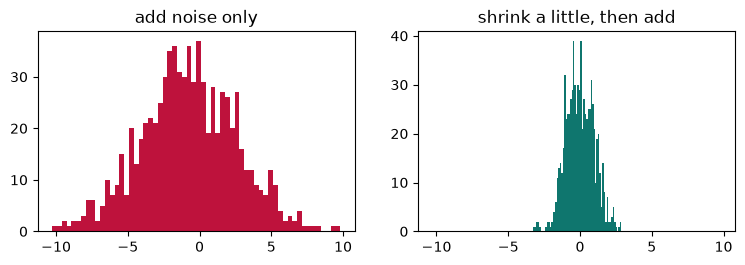

In [3]:
# Why shrink? Noise the 784 pixels of a 3 for 1,000 steps, without and with the shrink
x_test, y_test = mnist('test')
three = x_test[90].flatten()                       # the held 3 of Lectures 2 and 3
torch.manual_seed(1)
naive, shrunk = three.clone(), three.clone()
for t in range(1, T + 1):
    naive = naive + beta[t].sqrt() * torch.randn(784)
    shrunk = alpha[t].sqrt() * shrunk + beta[t].sqrt() * torch.randn(784)
print(f'spread after 1,000 steps: add only {naive.std():.2f}, shrink then add {shrunk.std():.2f}')
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6), sharex=True)
ax[0].hist(naive, 60, color='#BE123C'); ax[0].set_title('add noise only')
ax[1].hist(shrunk, 60, color='#0F766E'); ax[1].set_title('shrink a little, then add')
plt.show()

## 1.2 A toy schedule, by hand

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#toy-schedule/1). Five big steps so that every number fits on a slide. Real models use 1,000 tiny steps.

In [4]:
toy_beta = [0.1, 0.2, 0.3, 0.5, 0.8]
ab = 1.0
print(' t   beta  alpha  alpha_bar = previous x alpha   sqrt(ab)  sqrt(1-ab)')
for t, b in enumerate(toy_beta, 1):
    a = 1 - b
    print(f'{t:2d}   {b:.1f}   {a:.1f}    {ab:.4f} x {a:.1f} = {ab * a:.4f}        {math.sqrt(ab * a):.3f}     {math.sqrt(1 - ab * a):.3f}')
    ab *= a

 t   beta  alpha  alpha_bar = previous x alpha   sqrt(ab)  sqrt(1-ab)
 1   0.1   0.9    1.0000 x 0.9 = 0.9000        0.949     0.316
 2   0.2   0.8    0.9000 x 0.8 = 0.7200        0.849     0.529
 3   0.3   0.7    0.7200 x 0.7 = 0.5040        0.710     0.704
 4   0.5   0.5    0.5040 x 0.5 = 0.2520        0.502     0.865
 5   0.8   0.2    0.2520 x 0.2 = 0.0504        0.224     0.974


In [5]:
# Forward, step by step, on the ink pixel with fixed draws
toy_eps = [0.3, -0.5, 0.6, -1.2, 0.5]
x = 1.0
for t, (b, e) in enumerate(zip(toy_beta, toy_eps), 1):
    new = math.sqrt(1 - b) * x + math.sqrt(b) * e
    print(f't={t}: sqrt({1 - b:.1f}) * {x:+.3f} + sqrt({b:.1f}) * {e:+.1f} = {new:+.3f}')
    x = new
toy_x5 = x

t=1: sqrt(0.9) * +1.000 + sqrt(0.1) * +0.3 = +1.044
t=2: sqrt(0.8) * +1.044 + sqrt(0.2) * -0.5 = +0.710
t=3: sqrt(0.7) * +0.710 + sqrt(0.3) * +0.6 = +0.922
t=4: sqrt(0.5) * +0.922 + sqrt(0.5) * -1.2 = -0.196
t=5: sqrt(0.2) * -0.196 + sqrt(0.8) * +0.5 = +0.359


## 1.3 The shortcut

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#shortcut-q/1). $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$: any step in one line.

In [6]:
def q_sample(x0, t, eps):
    a = alpha_bar[t]
    return a.sqrt() * x0 + (1 - a).sqrt() * eps

# two toy steps collapse into one: the combined noise of eps1 = 0.3 and eps2 = -0.5
e = (math.sqrt(0.8) * math.sqrt(0.1) * 0.3 + math.sqrt(0.2) * -0.5) / math.sqrt(0.28)
print(f'combined eps = {e:.3f}; one jump: sqrt(0.72) * 1 + sqrt(0.28) * {e:.3f} = {math.sqrt(0.72) + math.sqrt(0.28) * e:.3f}')

combined eps = -0.262; one jump: sqrt(0.72) * 1 + sqrt(0.28) * -0.262 = 0.710


step by step: mean 0.715 sd 0.699 · one jump: mean 0.723 sd 0.706 · exact: mean 0.724 sd 0.690


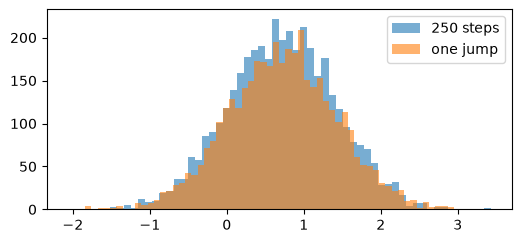

In [7]:
# Step by step or one jump: the same distribution (4,000 runs each, t = 250)
t, n = 250, 4000
steps = torch.ones(n)
for s in range(1, t + 1):
    steps = alpha[s].sqrt() * steps + beta[s].sqrt() * torch.randn(n)
jump = q_sample(torch.ones(n), t, torch.randn(n))
print(f'step by step: mean {steps.mean():.3f} sd {steps.std():.3f} · one jump: mean {jump.mean():.3f} sd {jump.std():.3f}'
      f' · exact: mean {alpha_bar[t].sqrt():.3f} sd {(1 - alpha_bar[t]).sqrt():.3f}')
plt.figure(figsize=(6, 2.6)); plt.hist(steps, 60, alpha=.6, label='250 steps'); plt.hist(jump, 60, alpha=.6, label='one jump'); plt.legend(); plt.show()

## 1.4 The real schedule

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#schedule/1). Our running example: the ink pixel at $t=250$ with $\varepsilon=-0.5$.

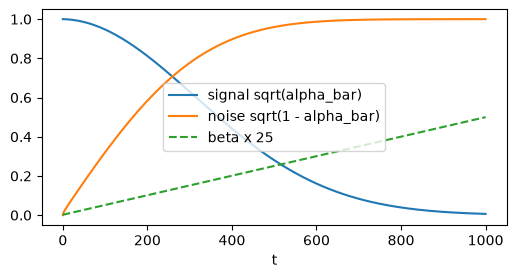

alpha_bar[250] = 0.5241 (a product of 250 alphas); x_250 = 0.724 * 1 + 0.690 * (-0.5) = 0.379


In [8]:
t = torch.arange(T + 1)
plt.figure(figsize=(6, 2.8))
plt.plot(t, alpha_bar.sqrt(), label='signal sqrt(alpha_bar)'); plt.plot(t, (1 - alpha_bar).sqrt(), label='noise sqrt(1 - alpha_bar)')
plt.plot(t, beta * 25, '--', label='beta x 25'); plt.legend(); plt.xlabel('t'); plt.show()
a = alpha_bar[250]
print(f'alpha_bar[250] = {a:.4f} (a product of 250 alphas); x_250 = {a.sqrt():.3f} * 1 + {(1 - a).sqrt():.3f} * (-0.5) = {q_sample(1.0, 250, -0.5):.3f}')

## 1.5 Watch our 3 dissolve

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#film/1). Every image ends as $\mathcal N(0, I)$: the signal is shrunk to zero, and what is left is Gaussian because we made it so.

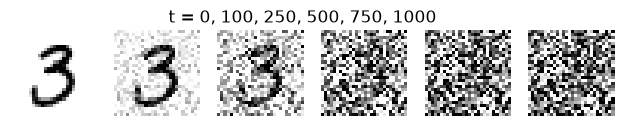

at t = 1000 the 784 values have mean -0.01 and sd 1.02: like N(0, 1)


In [9]:
torch.manual_seed(2026)
eps_fixed = torch.randn(784)
levels = [0, 100, 250, 500, 750, 1000]
show([q_sample(three, t, eps_fixed) for t in levels], title='t = ' + ', '.join(map(str, levels)))
x_end = q_sample(three, 1000, eps_fixed)
print(f'at t = 1000 the 784 values have mean {x_end.mean():.2f} and sd {x_end.std():.2f}: like N(0, 1)')

## 2.1 What we want

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#reverse-q/1). Going back needs $q(x_{t-1}\mid x_t)\propto q(x_t\mid x_{t-1})\,q(x_{t-1})$, and the prior over noisy images is unknown. For one pixel it is known.

In [10]:
# One pixel of our 3, across the training set: how often is it ink?
x_train, y_train = mnist('train')
r, c = 22, 16
pi = (x_train[:, 0, r, c] > 0).float().mean().item()
print(f'pixel ({r}, {c}): our 3 has {three[r * 28 + c]:+.2f}; ink in {pi:.1%} of training images')

def p_ink(xt, t, pi=pi, ab=alpha_bar):
    # Bayes: the log-likelihood ratio of ink vs paper is 2 sqrt(ab) x_t / (1 - ab): a sigmoid of x_t
    a = ab[t]
    return torch.sigmoid(torch.as_tensor(math.log(pi / (1 - pi)) + 2 * a.sqrt() * xt / (1 - a)))

def best_eps(xt, t, pi=pi, ab=alpha_bar):
    # the best possible noise guess for this one-pixel dataset: E[eps | x_t]
    x0_hat = 2 * p_ink(xt, t, pi, ab) - 1
    return (xt - ab[t].sqrt() * x0_hat) / (1 - ab[t]).sqrt()

xt = q_sample(1.0, 250, -0.5)
print(f'x_250 = {xt:.3f}: P(ink) = {p_ink(xt, 250):.2f}, best guess x0 = {2 * p_ink(xt, 250) - 1:.2f}, best noise guess = {best_eps(xt, 250):.3f}')

pixel (22, 16): our 3 has +0.95; ink in 35.0% of training images
x_250 = 0.379: P(ink) = 0.63, best guess x0 = 0.26, best noise guess = 0.276


## 2.2 Big jumps back are hard, small ones easy

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#big-jump/1). The exact distribution of the pixel some steps back is a mixture of two Gaussians: two bumps for a big jump, one bell for a small step.

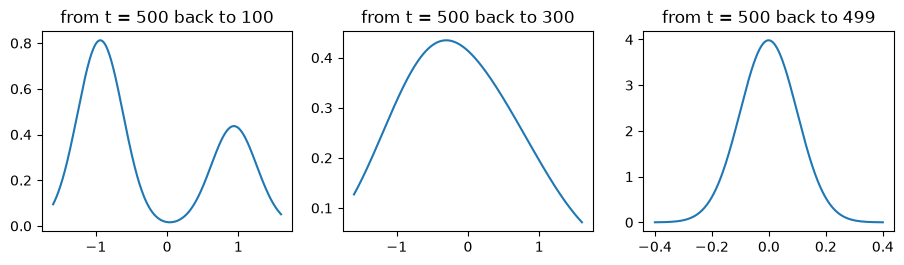

In [11]:
def reverse_density(xt, t, s, grid):
    # q(x_s | x_t) = sum over ink/paper of P(x0 | x_t) q(x_s | x_t, x0), for s < t
    ats = alpha_bar[t] / alpha_bar[s]
    var = (1 - alpha_bar[s]) * (1 - ats) / (1 - alpha_bar[t])
    P = p_ink(torch.tensor(xt), t)
    dens = 0
    for x0, w in ((1.0, P), (-1.0, 1 - P)):
        mean = (alpha_bar[s].sqrt() * (1 - ats) * x0 + ats.sqrt() * (1 - alpha_bar[s]) * xt) / (1 - alpha_bar[t])
        dens = dens + w * torch.exp(-(grid - mean) ** 2 / (2 * var)) / torch.sqrt(2 * math.pi * var)
    return dens

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, s in zip(axes, [100, 300, 499]):
    grid = torch.linspace(-1.6, 1.6, 400) if s < 450 else torch.linspace(-.4, .4, 400)
    ax.plot(grid, reverse_density(0.0, 500, s, grid)); ax.set_title(f'from t = 500 back to {s}')
plt.show()

## 2.3 Guess the noise

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#guess-noise/1). If we knew $\varepsilon$, $x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\varepsilon)/\sqrt{\bar\alpha_t}$. A network guesses $\varepsilon$.

In [12]:
x2, e = 0.7098, -0.2622                       # the toy's x_2 and its combined noise
print(f'x0 = ({x2} - sqrt(0.28) * ({e})) / sqrt(0.72) = {(x2 - math.sqrt(0.28) * e) / math.sqrt(0.72):.3f}')

x0 = (0.7098 - sqrt(0.28) * (-0.2622)) / sqrt(0.72) = 1.000


## 2.4 One step back

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#reverse-step/1). $x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\hat\varepsilon\big)+\sqrt{\beta_t}\,z$, and no noise at the last step.

In [13]:
def reverse_step(xt, t, eps_hat, z, beta, alpha, alpha_bar):
    mean = (xt - beta[t] / (1 - alpha_bar[t]).sqrt() * eps_hat) / alpha[t].sqrt()
    return mean + (beta[t].sqrt() * z if t > 1 else 0)

## 3.1 The training example

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#tuple/1). Pick $x_0$, $t$ and $\varepsilon$; make $x_t$. The network sees $(x_t,t)$; the target is the $\varepsilon$ we drew.

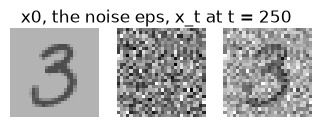

In [14]:
t = 250
eps = torch.randn(784)
show([three, eps, q_sample(three, t, eps)], title='x0, the noise eps, x_t at t = 250', vmin=-2.5, vmax=2.5)

## 3.2 Why the network needs t

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#why-t/1). The same pixel value means different things at different noise levels.

t = 50: best guess of x0 for x_t = 0.38 is +1.00
t = 250: best guess of x0 for x_t = 0.38 is +0.26
t = 900: best guess of x0 for x_t = 0.38 is -0.29


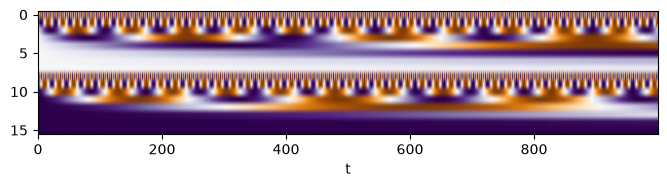

In [15]:
for t in [50, 250, 900]:
    print(f't = {t}: best guess of x0 for x_t = 0.38 is {2 * p_ink(0.38, t) - 1:+.2f}')
def time_features(t, dim=64):
    freq = torch.exp(-math.log(10000) * torch.arange(dim // 2) / (dim // 2 - 1))
    ang = t.float()[:, None] * freq
    return torch.cat([ang.sin(), ang.cos()], 1)
plt.figure(figsize=(8, 1.6)); plt.imshow(time_features(torch.arange(1, T + 1), 16).T, aspect='auto', cmap='PuOr'); plt.xlabel('t'); plt.show()

## 3.3 The loss

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#loss-hand/1). Squared error between the noise and its guess. The same $x_t$ can come from different noises, so the best guess is their average and the loss cannot reach zero.

In [16]:
eps_ink = -0.5
eps_paper = (xt + alpha_bar[250].sqrt()) / (1 - alpha_bar[250]).sqrt()
P = p_ink(xt, 250)
print(f'ink with eps = {eps_ink}, or paper with eps = {eps_paper:.2f}; best guess = {P:.2f} x {eps_ink} + {1 - P:.2f} x {eps_paper:.2f} = {best_eps(xt, 250):.3f}')
print(f'squared error for our draw: ({eps_ink} - {best_eps(xt, 250):.3f})^2 = {(eps_ink - best_eps(xt, 250)) ** 2:.2f}')

ink with eps = -0.5, or paper with eps = 1.60; best guess = 0.63 x -0.5 + 0.37 x 1.60 = 0.276
squared error for our draw: (-0.5 - 0.276)^2 = 0.60


## 3.4 The network

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#mlp/1). An MLP for 2-D points; a U-Net (with the time embedding in every block) for images.

In [17]:
class ToyDenoiser(nn.Module):
    # eps_hat(x, t[, c]): [x, y, 16 time features (, one-hot part)] -> 3 x 128 SiLU -> 2
    def __init__(self, n_parts=0, width=128, tdim=16):
        super().__init__()
        self.n_parts, self.tdim = n_parts, tdim
        din = 2 + tdim + (n_parts + 1 if n_parts else 0)
        self.net = nn.Sequential(nn.Linear(din, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(), nn.Linear(width, 2))
    def forward(self, x, t, c=None):
        parts = [x, time_features(t, self.tdim)]
        if self.n_parts: parts.append(F.one_hot(c, self.n_parts + 1).float())
        return self.net(torch.cat(parts, 1))

class TimeBlock(nn.Module):
    def __init__(self, cin, cout, temb=64):
        super().__init__()
        self.conv1, self.norm1 = nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(8, cout)
        self.time = nn.Linear(temb, cout)                       # the time embedding, added in every block
        self.conv2, self.norm2 = nn.Conv2d(cout, cout, 3, padding=1), nn.GroupNorm(8, cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, h):
        y = F.silu(self.norm1(self.conv1(x))) + self.time(h)[:, :, None, None]
        return F.silu(self.norm2(self.conv2(y)) + self.skip(x))

class TinyUNet(nn.Module):
    # 28 -> 14 -> 7 -> 14 -> 28 with skip connections; n_classes > 0 adds a label (10 = no label)
    def __init__(self, n_classes=0):
        super().__init__()
        self.time_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.label = nn.Embedding(n_classes + 1, 64) if n_classes else None
        self.encoder1, self.down1 = TimeBlock(1, 32), nn.Conv2d(32, 64, 4, 2, 1)
        self.encoder2, self.down2 = TimeBlock(64, 64), nn.Conv2d(64, 128, 4, 2, 1)
        self.middle = TimeBlock(128, 128)
        self.up1, self.decoder1 = nn.Conv2d(128, 64, 3, padding=1), TimeBlock(128, 64)
        self.up2, self.decoder2 = nn.Conv2d(64, 32, 3, padding=1), TimeBlock(64, 32)
        self.head = nn.Conv2d(32, 1, 1)
    def forward(self, x, t, c=None):
        h = self.time_mlp(time_features(t))
        if self.label is not None: h = h + self.label(c)
        e1 = self.encoder1(x, h); e2 = self.encoder2(self.down1(e1), h)
        m = self.middle(self.down2(e2), h)
        d1 = self.decoder1(torch.cat([self.up1(F.interpolate(m, size=e2.shape[-2:])), e2], 1), h)
        d2 = self.decoder2(torch.cat([self.up2(F.interpolate(d1, size=e1.shape[-2:])), e1], 1), h)
        return self.head(d2)

print('MLP parameters', sum(p.numel() for p in ToyDenoiser().parameters()), '· U-Net parameters', sum(p.numel() for p in TinyUNet().parameters()))

MLP parameters 35714 · U-Net parameters 814145


## 3.5 Training, live

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#train-code/1). The training step is eight lines. We train the 2-D smiley here (fewer steps than the slides' model) and take one real step on the MNIST network.

6,000 steps in 13 s; loss 0.271 -> 0.180


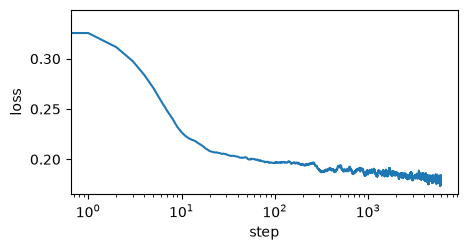

In [18]:
def smiley(n, seed=0):
    # points of a smiley face, with part labels: 0 outline, 1 eyes, 2 mouth
    g = np.random.default_rng(seed)
    part = g.choice(3, size=n, p=[0.5, 0.2, 0.3]); x = np.zeros((n, 2))
    k = part == 0; a = g.uniform(0, 2 * np.pi, k.sum()); r = 1 + 0.025 * g.standard_normal(k.sum()); x[k] = np.c_[r * np.cos(a), r * np.sin(a)]
    k = part == 1; side = g.choice([-1, 1], size=k.sum()); x[k] = np.c_[0.38 * side + 0.06 * g.standard_normal(k.sum()), 0.32 + 0.09 * g.standard_normal(k.sum())]
    k = part == 2; a = g.uniform(np.pi + 0.45, 2 * np.pi - 0.45, k.sum()); r = 0.58 + 0.025 * g.standard_normal(k.sum()); x[k] = np.c_[r * np.cos(a), 0.08 + r * np.sin(a)]
    return torch.tensor(x, dtype=torch.float32), torch.tensor(part)

def train_step(model, x0, opt, c=None, null=None, p_drop=0.3):
    t = torch.randint(1, T + 1, (x0.shape[0],))               # a level per example
    eps = torch.randn_like(x0)                                # the noise: also the target
    a = alpha_bar[t].view(-1, *([1] * (x0.dim() - 1)))
    xt = a.sqrt() * x0 + (1 - a).sqrt() * eps                 # the shortcut
    if c is not None:                                         # hide some labels, for guidance
        c = torch.where(torch.rand(len(c)) < p_drop, torch.full_like(c, null), c)
    eps_hat = model(xt, t) if c is None else model(xt, t, c)  # the guess
    loss = ((eps - eps_hat) ** 2).mean()                      # squared error
    opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

torch.manual_seed(667)
data, parts = smiley(100_000)
toy = ToyDenoiser()
opt = torch.optim.Adam(toy.parameters(), lr=2e-3)
history, t0 = [], time.time()
for step in range(1, 6001):
    ix = torch.randint(len(data), (1024,))
    history.append(train_step(toy, data[ix], opt))
print(f'6,000 steps in {time.time() - t0:.0f} s; loss {np.mean(history[:100]):.3f} -> {np.mean(history[-500:]):.3f}')
plt.figure(figsize=(5, 2.4)); plt.semilogx(np.convolve(history, np.ones(50) / 50, 'valid')); plt.xlabel('step'); plt.ylabel('loss'); plt.show()

In [19]:
# The MNIST U-Net we use from here on (30,000 such steps on a laptop GPU), and one real training step on a copy
unet = TinyUNet(); unet.load_state_dict(checkpoint('mnist-ddpm')['model']); unet.eval()
copy = TinyUNet(); copy.load_state_dict(unet.state_dict())
opt = torch.optim.Adam(copy.parameters(), lr=2e-4)
batch = x_train[:64]
torch.manual_seed(3)
print(f'one training step on 64 images: loss {train_step(copy, batch, opt):.4f}')

one training step on 64 images: loss 0.0182


## 3.6 What the network believes

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#x0film/1). From $\hat\varepsilon$ we get the network's guess of the clean image, $\hat x_0$: a blurry average at high noise, sharp at low noise.

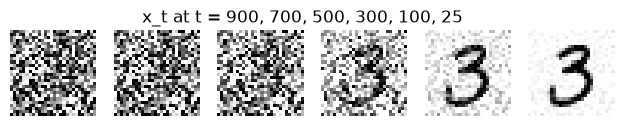

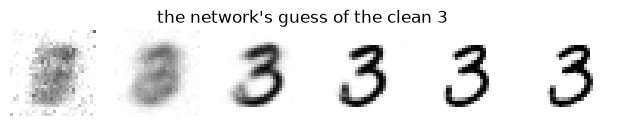

In [20]:
@torch.no_grad()
def x0_guess(model, xt, t):
    eps_hat = model(xt, torch.full((len(xt),), t))
    return (xt - (1 - alpha_bar[t]).sqrt() * eps_hat) / alpha_bar[t].sqrt()
levels = [900, 700, 500, 300, 100, 25]
x3 = three.view(1, 1, 28, 28)
noisy = [q_sample(x3, t, eps_fixed.view(1, 1, 28, 28)) for t in levels]
show([n[0] for n in noisy], title='x_t at t = ' + ', '.join(map(str, levels)))
show([x0_guess(unet, n, t)[0].clamp(-1, 1) for n, t in zip(noisy, levels)], title="the network's guess of the clean 3")

## 4.1 One step back, by hand

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#step-hand/1). The pixel at $t=250$, with the best possible noise guess.

In [21]:
eps_hat = best_eps(xt, 250)
nxt = reverse_step(xt, 250, eps_hat, z=0.8, beta=beta, alpha=alpha, alpha_bar=alpha_bar)
print(f'x_250 = {xt:.3f}, eps_hat = {eps_hat:.3f}, x_249 = {nxt:.3f}')

x_250 = 0.379, eps_hat = 0.276, x_249 = 0.435


## 4.2 The toy, all the way back

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#toy-reverse/1). Start from the toy's $x_5$ and step back with the best possible noise guess for the one-pixel dataset. Then run it many times: about a third end as ink, as in the data.

In [22]:
tb = torch.tensor([0.0] + toy_beta); ta = 1 - tb; tab = torch.cumprod(ta, 0)
toy_z = {5: -0.3, 4: 0.5, 3: 0.2, 2: -0.4, 1: 0.0}
x = torch.tensor(toy_x5)
for t in range(5, 0, -1):
    e = best_eps(x, t, ab=tab)
    new = reverse_step(x, t, e, toy_z[t], tb, ta, tab)
    print(f't={t}: x={x:+.3f}  eps_hat={e:+.3f}  ->  x_{t - 1} = {new:+.3f}')
    x = new
runs = torch.randn(2000)
for t in range(5, 0, -1):
    runs = reverse_step(runs, t, best_eps(runs, t, ab=tab), torch.randn(2000), tb, ta, tab)
print(f'2,000 runs from noise: {(runs > 0).float().mean():.1%} end as ink (the data: {pi:.1%})')

t=5: x=+0.359  eps_hat=+0.420  ->  x_4 = -0.235
t=4: x=-0.235  eps_hat=-0.019  ->  x_3 = +0.036
t=3: x=+0.036  eps_hat=+0.306  ->  x_2 = -0.003
t=2: x=-0.003  eps_hat=+0.490  ->  x_1 = -0.390
t=1: x=-0.390  eps_hat=+1.765  ->  x_0 = -0.999
2,000 runs from noise: 37.7% end as ink (the data: 35.0%)


## 4.3 The loop

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#sample-code/1). Start from pure noise; guess, step, repeat a thousand times.

16 digits, 1,000 steps: 77 s on cpu


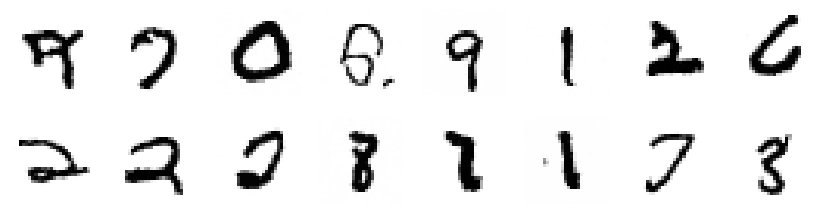

In [23]:
@torch.no_grad()
def sample(model, n, seed=0, eps_fn=None, sigma=True, keep=()):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 1, 28, 28, generator=g)
    kept = {}
    for t in range(T, 0, -1):
        tt = torch.full((n,), t)
        eps_hat = eps_fn(x, t) if eps_fn else model(x, tt)
        if t in keep: kept[t] = ((x - (1 - alpha_bar[t]).sqrt() * eps_hat) / alpha_bar[t].sqrt()).clamp(-1, 1)
        z = torch.randn(x.shape, generator=g) if sigma else torch.zeros_like(x)
        x = reverse_step(x, t, eps_hat, z, beta, alpha, alpha_bar)
    return x, kept
t0 = time.time()
digits, kept = sample(unet, 16, seed=1, keep=(900, 700, 500, 300, 100))
print(f'16 digits, 1,000 steps: {time.time() - t0:.0f} s on {device}')
show(digits.clamp(-1, 1), n_rows=2)

## 4.4 Watch it

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#sampler2d/1). The same loop on the 2-D smiley, and the MNIST network's guess of the finished digit along one run.

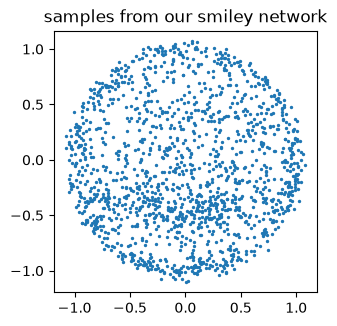

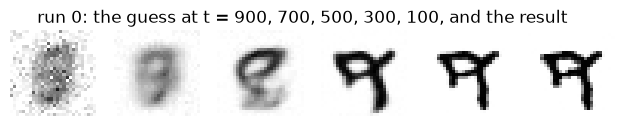

In [24]:
@torch.no_grad()
def sample_2d(model, n, seed=0, c=None, w=0.0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g)
    for t in range(T, 0, -1):
        tt = torch.full((n,), t)
        if c is None: e = model(x, tt)
        else:
            e_none = model(x, tt, torch.full((n,), model.n_parts)); e_c = model(x, tt, torch.full((n,), c))
            e = e_none + w * (e_c - e_none)
        x = reverse_step(x, t, e, torch.randn(x.shape, generator=g), beta, alpha, alpha_bar)
    return x
pts = sample_2d(toy, 1500, seed=4)
plt.figure(figsize=(3.4, 3.4)); plt.scatter(*pts.T, s=2); plt.axis('equal'); plt.title('samples from our smiley network'); plt.show()
show([kept[t][0] for t in (900, 700, 500, 300, 100)] + [digits[0].clamp(-1, 1)], title="run 0: the guess at t = 900, 700, 500, 300, 100, and the result")

## 4.5 Why the fresh noise?

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#why-noise/1). Keep only the mean of each step and every sample collapses to the same thing.

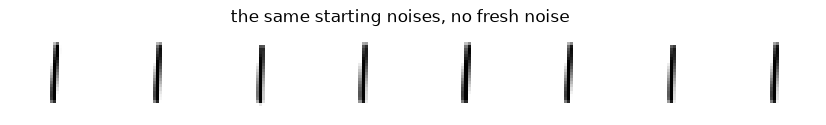

In [25]:
same_starts, _ = sample(unet, 8, seed=1, sigma=False)
show(same_starts.clamp(-1, 1), title='the same starting noises, no fresh noise')

## 4.6 New digits

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#samples64/1). Sixty-four samples, and the whole method on a napkin: train with the shortcut and a squared error; sample with the loop.

## 5.1 A 3 on demand

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#label/1). One added line: a label embedding next to the time embedding. To save time we sample with 50 DDIM steps (Part 6) in this part.

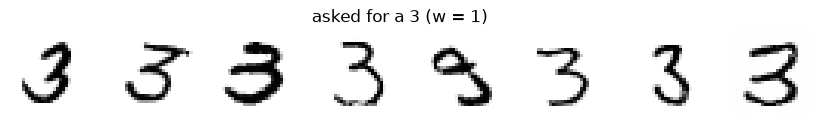

In [26]:
@torch.no_grad()
def ddim(eps_fn, n, steps, seed=0, shape=(1, 28, 28), ab=alpha_bar):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, *shape, generator=g)
    ts = torch.linspace(T, 1, steps).round().long().tolist() + [0]
    for t, t_next in zip(ts[:-1], ts[1:]):
        eps_hat = eps_fn(x, t)
        x0_hat = (x - (1 - ab[t]).sqrt() * eps_hat) / ab[t].sqrt()     # jump to the guess...
        x = ab[t_next].sqrt() * x0_hat + (1 - ab[t_next]).sqrt() * eps_hat   # ...re-noise to the next level
    return x
cond = TinyUNet(n_classes=10); cond.load_state_dict(checkpoint('mnist-cfg')['model']); cond.eval()
def guided(c, w):
    def fn(x, t):
        tt = torch.full((len(x),), t)
        e_none = cond(x, tt, torch.full((len(x),), 10))
        return e_none if w == 0 else e_none + w * (cond(x, tt, torch.full((len(x),), c)) - e_none)
    return fn
show(ddim(guided(3, 1.0), 8, 50, seed=5).clamp(-1, 1), title='asked for a 3 (w = 1)')

## 5.2 Classifier-free guidance

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#cfg/1). $\hat\varepsilon_{guided}=\hat\varepsilon(\varnothing)+w\,(\hat\varepsilon(c)-\hat\varepsilon(\varnothing))$.

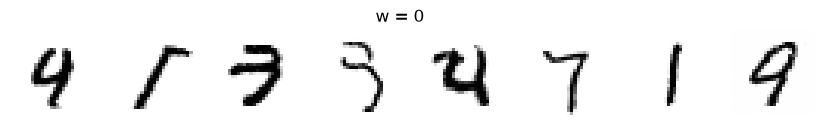

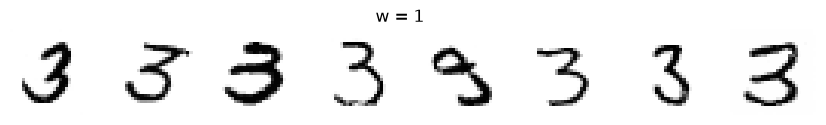

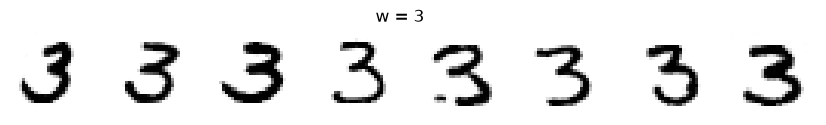

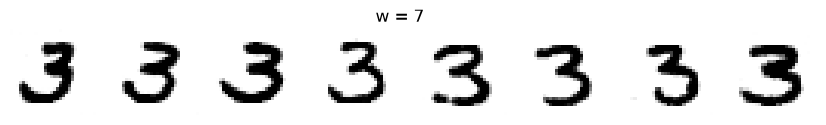

In [27]:
for w in [0, 1, 3, 7]:
    show(ddim(guided(3, w), 8, 50, seed=5).clamp(-1, 1), title=f'w = {w}')

## 5.3 The guidance dial

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#dial/1). More $w$: more 3-like, less variety. A separate classifier measures it.

In [28]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 49, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)
clf = Classifier(); clf.load_state_dict(checkpoint('mnist-classifier')['model']); clf.eval()
for w in [0, 1, 2, 5]:
    xs = ddim(guided(3, w), 32, 50, seed=6).clamp(-1, 1)
    with torch.no_grad(): is3 = (clf(xs).argmax(1) == 3).float().mean()
    spread = torch.cdist(xs.flatten(1), xs.flatten(1)).sum() / (32 * 31)
    print(f'w = {w}: {is3:.0%} classified as 3, variety (mean pairwise distance) {spread:.1f}')

w = 0: 9% classified as 3, variety (mean pairwise distance) 19.3


w = 1: 88% classified as 3, variety (mean pairwise distance) 18.1


w = 2: 97% classified as 3, variety (mean pairwise distance) 17.5


w = 5: 100% classified as 3, variety (mean pairwise distance) 15.9


## 5.4 Latent diffusion

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#latent/1). Diffuse a 4 × 7 × 7 code instead of 784 pixels, then decode.

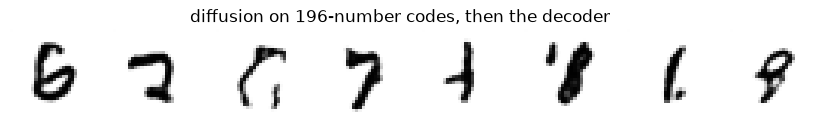

In [29]:
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1), nn.SiLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.SiLU(), nn.Conv2d(64, 64, 4, 2, 1), nn.SiLU(), nn.Conv2d(64, 4, 3, 1, 1))
        self.dec = nn.Sequential(nn.Conv2d(4, 64, 3, 1, 1), nn.SiLU(), nn.ConvTranspose2d(64, 64, 4, 2, 1), nn.SiLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.SiLU(), nn.Conv2d(32, 1, 3, 1, 1), nn.Tanh())
class LatentDenoiser(nn.Module):
    def __init__(self, ch=128):
        super().__init__()
        self.time_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.inp = nn.Conv2d(4, ch, 3, padding=1); self.blocks = nn.ModuleList([TimeBlock(ch, ch) for _ in range(4)]); self.out = nn.Conv2d(ch, 4, 3, padding=1)
    def forward(self, z, t):
        h = self.time_mlp(time_features(t)); y = self.inp(z)
        for b in self.blocks: y = b(y, h)
        return self.out(y)
ck = checkpoint('mnist-ae'); ae = ConvAE(); ae.load_state_dict(ck['model']); ae.eval()
lat = LatentDenoiser(); lat.load_state_dict(checkpoint('mnist-latent')['model']); lat.eval()
with torch.no_grad():
    z = ddim(lambda x, t: lat(x, torch.full((len(x),), t)), 8, 50, seed=7, shape=(4, 7, 7)) * ck['latent_std']
    show(ae.dec(z), title='diffusion on 196-number codes, then the decoder')

## 5.5 Text in

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#text/1). A sentence becomes word vectors (CLIP or T5); cross-attention lets each image position attend to them. Training is unchanged: image latents and captions instead of digits and labels.

## 6.1 DDIM: fewer steps

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#slow/1). Jump to the guess, then re-noise it to an earlier level: the same network, far fewer calls.

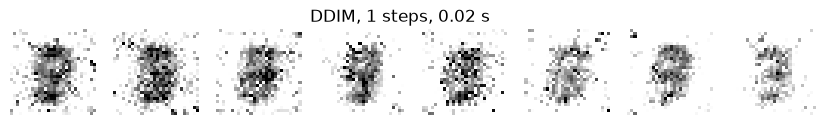

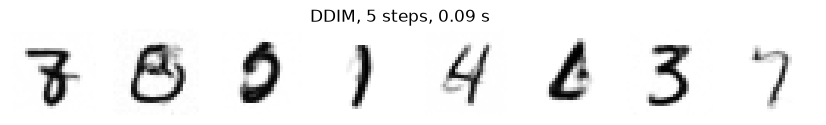

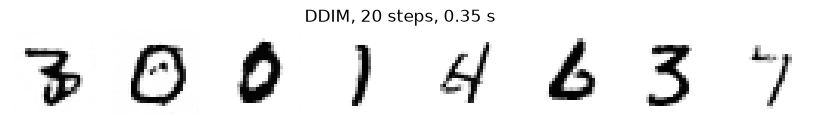

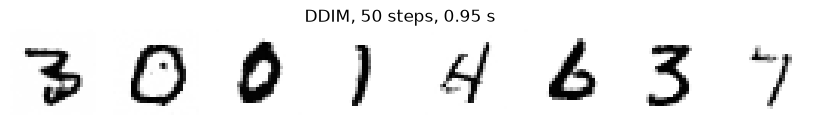

In [30]:
for steps in [1, 5, 20, 50]:
    t0 = time.time()
    xs = ddim(lambda x, t: unet(x, torch.full((len(x),), t)), 8, steps, seed=8)
    show(xs.clamp(-1, 1), title=f'DDIM, {steps} steps, {time.time() - t0:.2f} s')

## 6.2 The schedule matters

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#cosine/1). The linear schedule destroys the image early; the cosine schedule spreads it out.

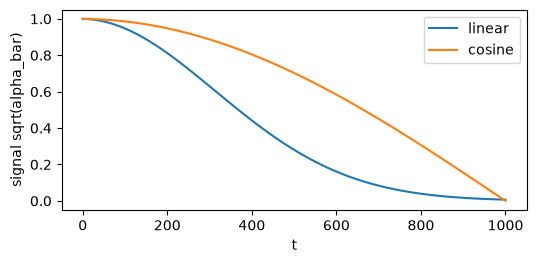

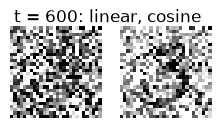

In [31]:
_, _, ab_cos = schedule('cosine')
plt.figure(figsize=(6, 2.6)); plt.plot(alpha_bar.sqrt(), label='linear'); plt.plot(ab_cos.sqrt(), label='cosine'); plt.legend(); plt.ylabel('signal sqrt(alpha_bar)'); plt.xlabel('t'); plt.show()
show([alpha_bar[600].sqrt() * three + (1 - alpha_bar[600]).sqrt() * eps_fixed, ab_cos[600].sqrt() * three + (1 - ab_cos[600]).sqrt() * eps_fixed], title='t = 600: linear, cosine')

## 7.1 Arrows to the data

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#score-def/1). The noise predictor is a score: $\hat\varepsilon\approx-\sqrt{1-\bar\alpha_t}\,\nabla_x\log q_t(x)$.

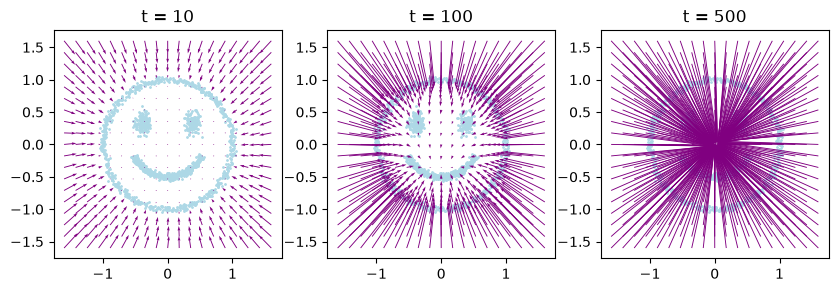

In [32]:
g = torch.linspace(-1.6, 1.6, 19); X, Y = torch.meshgrid(g, g, indexing='xy'); P = torch.stack([X.flatten(), Y.flatten()], 1)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, t in zip(axes, [10, 100, 500]):
    with torch.no_grad(): e = toy(P, torch.full((len(P),), t))
    arrow = -(1 - alpha_bar[t]).sqrt() * e                     # (1 - alpha_bar) x score
    ax.scatter(*data[:1500].T, s=1, c='lightblue'); ax.quiver(P[:, 0], P[:, 1], arrow[:, 0], arrow[:, 1], color='purple', angles='xy', scale_units='xy', scale=1, width=.004)
    ax.set_title(f't = {t}'); ax.set_aspect('equal')
plt.show()

## 7.2 It is a VAE

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-map/1). Latents $x_1,\dots,x_T$; the encoder is the fixed noising; each ELBO term is a KL between two Gaussians, which is a weighted squared noise error. Dropping the weights gives the loss we trained.

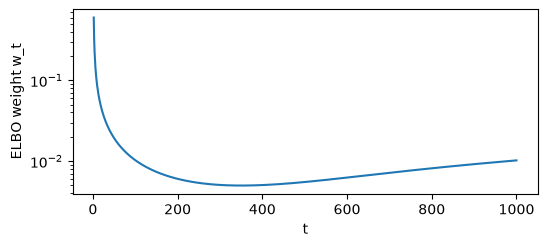

In [33]:
btil = beta[1:] * (1 - alpha_bar[:-1]) / (1 - alpha_bar[1:])
w = beta[2:] ** 2 / (2 * btil[1:] * alpha[2:] * (1 - alpha_bar[2:]))
plt.figure(figsize=(6, 2.4)); plt.semilogy(range(2, T + 1), w); plt.xlabel('t'); plt.ylabel('ELBO weight w_t'); plt.show()

## 7.3 Does it just copy?

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#ideal/1). The best possible denoiser of a finite training set is a weighted average of its points, and sampling with it returns them.

mean distance to a training point: ideal 0.0007, network 0.157


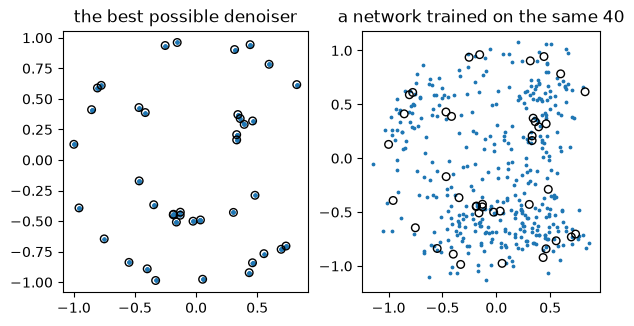

In [34]:
pts40, _ = smiley(40, seed=3)
def ideal_eps(x, t):
    a = alpha_bar[t]
    w = torch.softmax(-torch.cdist(x, a.sqrt() * pts40) ** 2 / (2 * (1 - a)), 1)
    return (x - a.sqrt() * (w @ pts40)) / (1 - a).sqrt()
g = torch.Generator().manual_seed(31); x = torch.randn(400, 2, generator=g)
with torch.no_grad():
    for t in range(T, 0, -1):
        x = reverse_step(x, t, ideal_eps(x, t), torch.randn(x.shape, generator=g), beta, alpha, alpha_bar)
small = ToyDenoiser(); opt = torch.optim.Adam(small.parameters(), lr=2e-3)
torch.manual_seed(0)
for step in range(4000): train_step(small, pts40[torch.randint(40, (512,))], opt)
y = sample_2d(small, 400, seed=31)
near = lambda a: torch.cdist(a, pts40).min(1).values.mean()
print(f'mean distance to a training point: ideal {near(x):.4f}, network {near(y):.3f}')
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
for ax, s, title in zip(axes, [x, y], ['the best possible denoiser', 'a network trained on the same 40']):
    ax.scatter(*s.T, s=3); ax.scatter(*pts40.T, s=30, facecolors='none', edgecolors='k'); ax.set_title(title); ax.set_aspect('equal')
plt.show()

## 7.4 Wrap-up

[Slides](https://nipunbatra.github.io/generative/lectures/lecture5/#frontier/1). 
**Exercises.** (1) Change the toy schedule to ten steps of β = 0.1 and redo 1.2 and 4.2 by hand. (2) Train the smiley without the shrink (noise only) and see what sampling does. (3) Sample the MNIST model with σ = 0 for only the last 100 steps. (4) Plot the classifier's 3-probability against w from 0 to 10.

**References.** Paras Chopra, *Diffusion Models from First Principles*; Ari Seff, *What are Diffusion Models?*; Deepia, *DDPM, Generative AI Animated*; Outlier, *Diffusion Models, Math Explained*; MIT 6.S183 *A Practical Introduction to Diffusion Models*; Ho et al. (2020); Song & Ermon (2019); Song, Meng & Ermon (2021); Ho & Salimans (2022); Rombach et al. (2022).